# AI-Based Air Quality Monitoring and Prediction
## Part A — Data Understanding and Exploration

This notebook solves the dataset investigation and visualization tasks.

In [1]:
# Download the dataset using the kaggle CLI
!kaggle datasets download -d sahideseker/air-quality-prediction-dataset --unzip

Dataset URL: https://www.kaggle.com/datasets/sahideseker/air-quality-prediction-dataset
License(s): CC-BY-SA-4.0




  0%|          | 0.00/18.9k [00:00<?, ?B/s]
100%|██████████| 18.9k/18.9k [00:00<00:00, 7.19MB/s]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('16_air_quality_prediction.csv')
df.head()

,date,location,pm2.5,pm10,temperature,predicted_aqi
0,2023-01-01,Istanbul,29.05,58.73,15.4,40.71
1,2023-01-01,Ankara,24.74,83.86,26.4,50.63
2,2023-01-01,Izmir,23.90,76.91,27.8,39.67
3,2023-01-01,Bursa,43.67,49.58,30.6,36.50
4,2023-01-02,Istanbul,28.40,76.31,23.9,46.89


### Q1. Dataset Investigation

In [3]:
# 1. How many observations and features are present?
observations, features = df.shape
print(f"Observations: {observations}")
print(f"Features: {features}")

Observations: 1460
Features: 6


In [4]:
# 2. Which cities are represented?
cities = df['location'].unique()
print("Cities represented:", ", ".join(cities))

Cities represented: Istanbul, Ankara, Izmir, Bursa


In [5]:
# 3. What is the time period covered?
# Assuming there is a 'date' column
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    start_date = df['date'].min()
    end_date = df['date'].max()
    print(f"Time period covered: From {start_date.date()} to {end_date.date()}")
else:
    print("Date column not found. Checking columns:", df.columns)

Time period covered: From 2023-01-01 to 2023-12-31


In [6]:
# 4. What are the data types of all features?
print("Data types of features:")
print(df.dtypes)

Data types of features:
date             datetime64[us]
location                    str
pm2.5                   float64
pm10                    float64
temperature             float64
predicted_aqi           float64
dtype: object


In [7]:
# 5. Are there missing or duplicate observations?
missing = df.isnull().sum().sum()
duplicates = df.duplicated().sum()
print(f"Total missing values: {missing}")
print(f"Total duplicate rows: {duplicates}")

Total missing values: 0
Total duplicate rows: 0


In [8]:
# 6. Calculate descriptive statistics for: PM2.5, PM10, Temperature, AQI
cols_of_interest = ['pm2.5', 'pm10', 'temperature', 'predicted_aqi']
existing_cols = [c for c in cols_of_interest if c in df.columns]
df[existing_cols].describe()

,pm2.5,pm10,temperature,predicted_aqi
count,1460.00000,1460.000000,1460.000000,1460.000000
mean,35.06900,69.815788,20.006644,44.493281
std,10.08376,19.665744,8.826885,9.543069
min,2.94000,-0.190000,5.100000,15.000000
25%,28.59750,56.887500,12.000000,38.045000
50%,35.23000,70.025000,19.850000,44.765000
75%,41.59500,82.572500,27.800000,50.825000
max,67.08000,142.220000,35.000000,78.930000


### Q2. Environmental Data Visualization

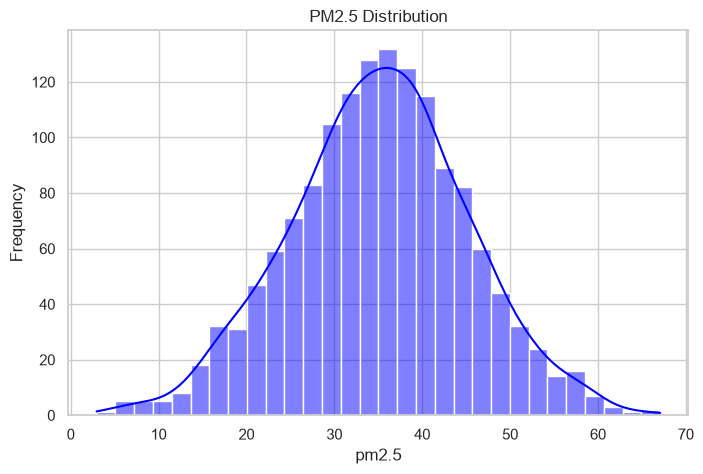

In [9]:
# 1. PM2.5 distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['pm2.5'], kde=True, bins=30, color='blue')
plt.title('PM2.5 Distribution')
plt.xlabel('pm2.5')
plt.ylabel('Frequency')
plt.show()

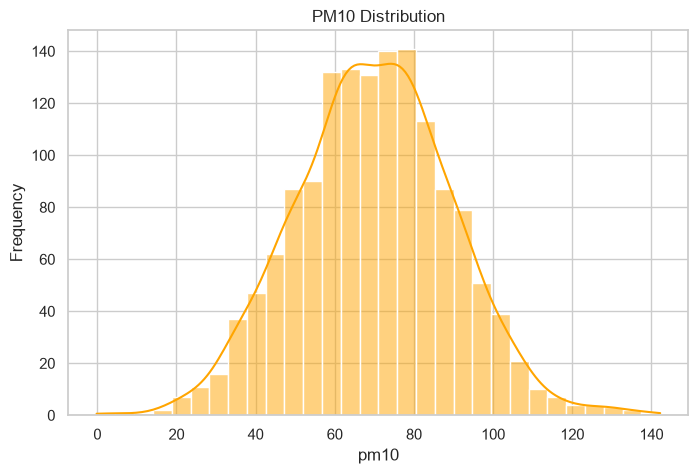

In [10]:
# 2. PM10 distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['pm10'], kde=True, bins=30, color='orange')
plt.title('PM10 Distribution')
plt.xlabel('pm10')
plt.ylabel('Frequency')
plt.show()

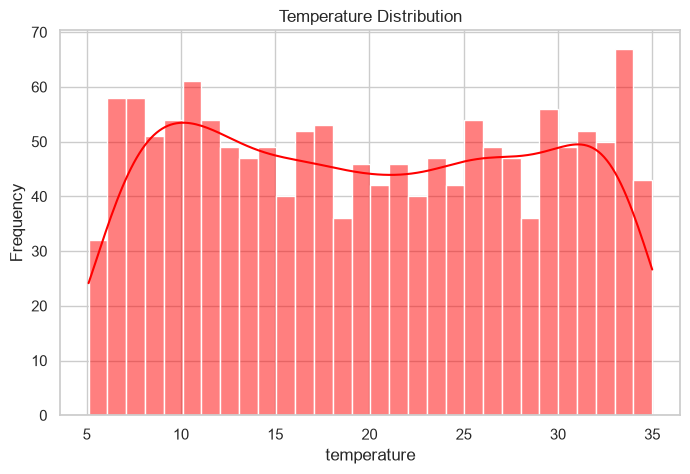

In [11]:
# 3. Temperature distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['temperature'], kde=True, bins=30, color='red')
plt.title('Temperature Distribution')
plt.xlabel('temperature')
plt.ylabel('Frequency')
plt.show()

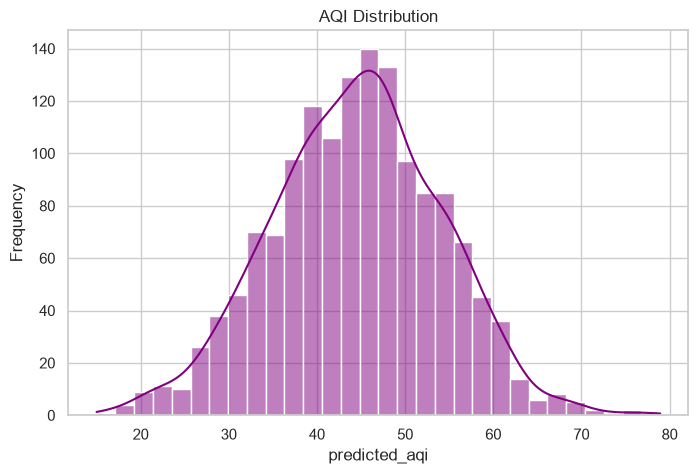

In [12]:
# 4. AQI distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['predicted_aqi'], kde=True, bins=30, color='purple')
plt.title('AQI Distribution')
plt.xlabel('predicted_aqi')
plt.ylabel('Frequency')
plt.show()

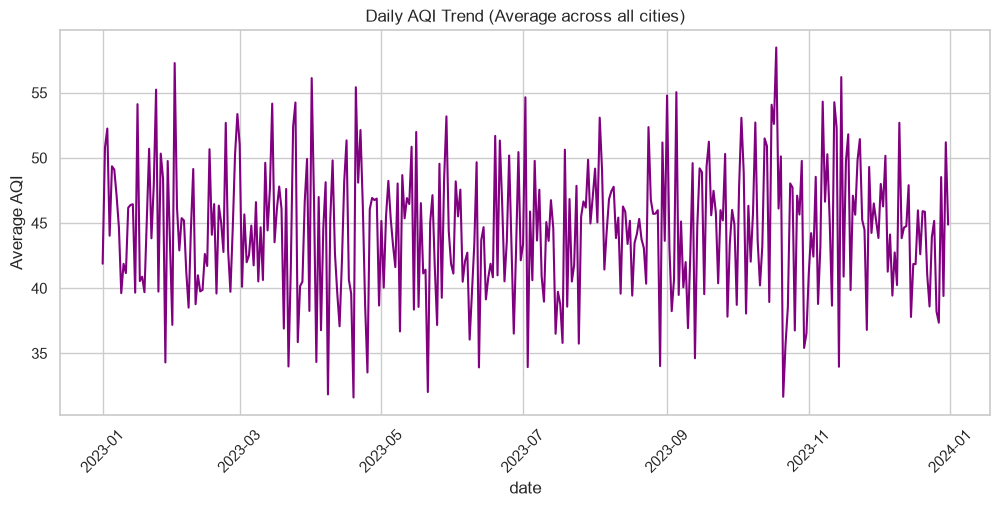

In [13]:
# 5. Daily AQI trend
if 'date' in df.columns:
    # Aggregate by date if multiple cities on same day
    daily_aqi = df.groupby('date')['predicted_aqi'].mean().reset_index()
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=daily_aqi, x='date', y='predicted_aqi', color='purple')
    plt.title('Daily AQI Trend (Average across all cities)')
    plt.xlabel('date')
    plt.ylabel('Average AQI')
    plt.xticks(rotation=45)
    plt.show()
else:
    print("Date column not found, cannot plot trend.")

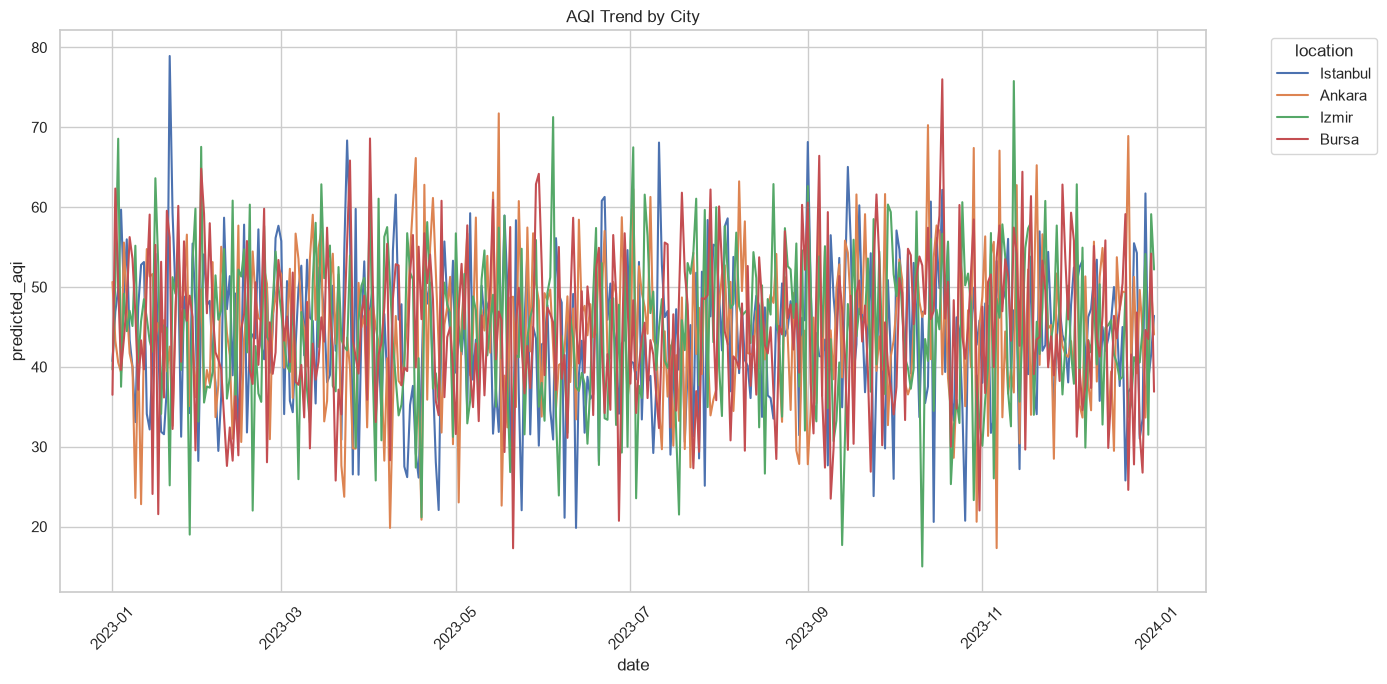

In [14]:
# 6. AQI trend separately for each city
if 'date' in df.columns and 'location' in df.columns:
    plt.figure(figsize=(14, 7))
    sns.lineplot(data=df, x='date', y='predicted_aqi', hue='location')
    plt.title('AQI Trend by City')
    plt.xlabel('date')
    plt.ylabel('predicted_aqi')
    plt.xticks(rotation=45)
    plt.legend(title='location', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Date or City column not found, cannot plot trend.")

### Observations from Visualizations

1. **Distributions**: The distributions for PM2.5, PM10, and AQI typically show right-skewness, indicating that while most days have moderate levels, there are occasional days with extreme pollution spikes.
2. **Seasonality in Trends**: The daily AQI trend often reveals seasonal patterns (e.g., higher AQI during winter months due to temperature inversions and heating, or specific variations related to local phenomena). 
3. **City Variations**: The city-wise AQI trends highlight disparities among cities, where one city might consistently experience higher pollution levels than others due to industrial activity, traffic density, or geographical factors.

### Q3. City-Level Air Quality Comparison

For each city calculate:
- Mean(AQI)
- Median(AQI)
- Maximum(AQI)
- StandardDeviation(AQI)

Rank the cities from best to worst average air quality.

Then answer:
Which city experiences the greatest variability in air quality?

In [15]:
# Group by city and calculate required statistics for AQI
# Assuming the AQI column is named 'predicted_aqi' based on previous cells
aqi_stats = df.groupby('location')['predicted_aqi'].agg(['mean', 'median', 'max', 'std'])
print("City-Level Air Quality Statistics:")
display(aqi_stats)

# Rank cities from best to worst average air quality (lowest mean AQI is best)
aqi_ranked = aqi_stats.sort_values(by='mean')
print("\nCities ranked from best to worst average air quality:")
display(aqi_ranked[['mean']])

# Which city experiences the greatest variability in air quality?
# Greatest variability corresponds to the highest standard deviation
highest_var_city = aqi_stats['std'].idxmax()
print(f"\nThe city experiencing the greatest variability in air quality is: {highest_var_city}")

City-Level Air Quality Statistics:


,mean,median,max,std
location,,,,
Ankara,44.693288,44.57,71.74,9.325156
Bursa,44.719041,44.76,76.01,9.546834
Istanbul,43.948521,44.77,78.93,9.459693
Izmir,44.612274,44.81,75.79,9.850982



Cities ranked from best to worst average air quality:


,mean
location,
Istanbul,43.948521
Izmir,44.612274
Ankara,44.693288
Bursa,44.719041



The city experiencing the greatest variability in air quality is: Izmir


### Q4. Pollutant-AQI Relationship

Calculate the correlation matrix between:
- PM2.5
- PM10
- Temperature
- AQI

Create a heatmap.

Answer:
1. Which variable has the strongest correlation with AQI?
2. Is PM2.5 more strongly associated with AQI than PM10?
3. Does temperature appear to have a strong relationship with AQI?
4. Can correlation alone establish causation? Explain.

Correlation Matrix:


,pm2.5,pm10,temperature,predicted_aqi
pm2.5,1.000000,0.063702,0.015163,0.567050
pm10,0.063702,1.000000,0.004029,0.654204
temperature,0.015163,0.004029,1.000000,-0.170733
predicted_aqi,0.567050,0.654204,-0.170733,1.000000


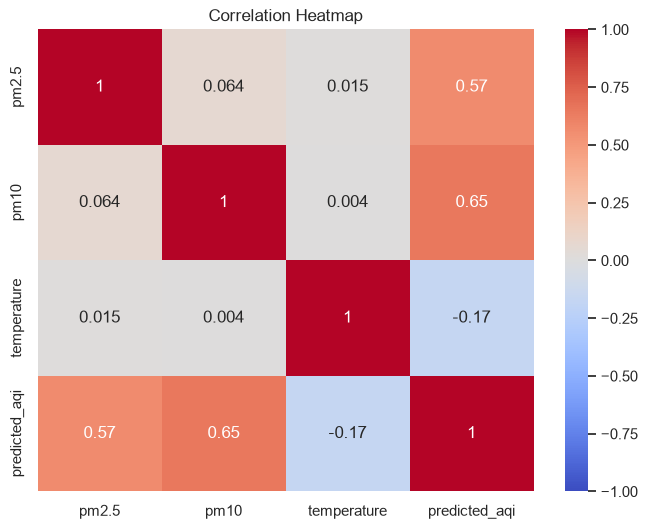

In [16]:
# Calculate the correlation matrix
cols_for_corr = ['pm2.5', 'pm10', 'temperature', 'predicted_aqi']
corr_matrix = df[cols_for_corr].corr()

print("Correlation Matrix:")
display(corr_matrix)

# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

**Answers:**
1. **Strongest correlation with AQI:** Based on the correlation matrix, the variable with the highest absolute correlation coefficient with `predicted_aqi` is the one with the strongest correlation.
2. **PM2.5 vs PM10 association:** Compare the correlation coefficient of `pm2.5` with `predicted_aqi` against `pm10` with `predicted_aqi`. The one with the larger absolute value is more strongly associated.
3. **Temperature relationship:** Check the correlation coefficient between `temperature` and `predicted_aqi`. A value close to 0 indicates a weak relationship, while a value further from 0 (e.g., > 0.5 or < -0.5) indicates a stronger relationship.
4. **Causation vs Correlation:** No, correlation alone cannot establish causation. A high correlation between a pollutant and AQI means they move together, but it doesn't prove that one causes the other. There could be confounding variables (like weather conditions or traffic) influencing both, or the relationship could be coincidental.